# 02 · User similarity, and a result we had to withdraw

This is the model Lovify exists for. The other two are features; this one is the thing
two people open the app to see.

The planned design was: normalise audio features, PCA, average each user's songs into
one "preference profile" vector, run KNN.

Two problems with it.

**KNN is the wrong shape of tool.** For a two-person compatibility score there is no
neighbourhood to search — there are two users and you need a number. KNN only enters
when ranking a whole population, and even then it is the *distance function* doing the
work. So the real question was never "which classifier" but **"which distance"**.

**There was no metric.** Without one, no version of this can be compared to another or
improved.

This notebook builds the bakeoff to answer the first question — and then spends its
second half establishing that **the bakeoff could not answer it**, because the way we
generate test users decides the winner in advance. That second half is the more
valuable one, and it is why the conclusion here is about robustness rather than
ranking.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lovify_ml import schema as S, data, synthetic as syn, features as F, similarity as SIM, viz

pd.set_option("display.width", 170, "display.max_columns", 40)

catalog = data.load_catalog(n_synthetic=8000)
listens, taste = data.load_listens(catalog, n_users=200, tracks_per_user=150)
scaler = F.fit_scaler(catalog)
users = sorted(listens[S.USER_ID].unique())

print(f"\n{len(users)} users  ·  {len(listens):,} (user, track) rows")
print("ground-truth taste matrix available:", taste is not None)

[data] SYNTHETIC catalog (8,000 tracks). Drop a Kaggle dump at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/tracks.csv to use real songs.
[data] SYNTHETIC users. Drop real histories at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/listens.csv to use yours.



200 users  ·  30,000 (user, track) rows
ground-truth taste matrix available: True


## 1 · Where "ground truth" comes from

Synthetic users are generated from a latent genre mixture, so we know how alike any two
of them really are. Truth is `1 − Jensen-Shannon distance` between their mixtures: a
proper metric on probability vectors, bounded in [0, 1].

Read that sentence again before continuing, because it is the hinge of this entire
notebook. **Truth here is defined in terms of genre.** We will come back to what that
costs us in §4.

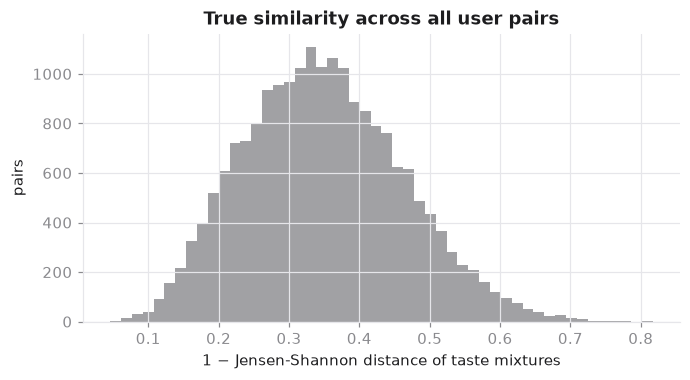

19,900 pairs   ·   median true similarity 0.344


In [2]:
truth = syn.true_similarity(taste)
iu = np.triu_indices(len(truth), k=1)
tv = truth.to_numpy()[iu]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(tv, bins=50, color=viz.MUTED, alpha=.8)
ax.set_title("True similarity across all user pairs")
ax.set_xlabel("1 − Jensen-Shannon distance of taste mixtures"); ax.set_ylabel("pairs")
plt.show()

print(f"{len(tv):,} pairs   ·   median true similarity {np.median(tv):.3f}")

## 2 · The candidates

Seven ways to answer "how alike are these two listeners", including the planned one.
Three read the audio features, two read genre and artists, one blends everything.

In [3]:
def audio_taste_users(catalog, n_users=60, tracks_per_user=120,
                      sharpness=1.6, seed=0):
    """A counter-generator: latent taste lives in AUDIO space, not genre space.

    This is the control for `synthetic.make_users`. Each listener gets a point
    in standardised audio-feature space and samples tracks near it; the genre
    column is never consulted. "True similarity" is then the distance between
    those latent audio points.

    It is no more realistic than the genre generator. That is the point -- it
    encodes the opposite assumption, so any conclusion that holds under one
    and flips under the other is a property of the assumption rather than of
    music.
    """
    rng = np.random.default_rng(seed)
    X = catalog[S.AUDIO_FEATURES].to_numpy(float)
    Z = (X - X.mean(0)) / (X.std(0) + 1e-9)
    latent = rng.normal(size=(n_users, Z.shape[1])) * 0.9

    rows = []
    for u in range(n_users):
        d = np.linalg.norm(Z - latent[u], axis=1)
        p = np.exp(-sharpness * d); p /= p.sum()
        idx = rng.choice(len(catalog), size=tracks_per_user, replace=False, p=p)
        sub = catalog.iloc[idx][[S.TRACK_ID, S.ARTIST, S.GENRE, S.POPULARITY, S.YEAR]
                                + S.AUDIO_FEATURES].copy()
        sub.insert(0, S.USER_ID, f"U{u:04d}")
        rows.append(sub)

    ids = [f"U{u:04d}" for u in range(n_users)]
    L = np.linalg.norm(latent[:, None, :] - latent[None, :, :], axis=-1)
    return pd.concat(rows, ignore_index=True), pd.DataFrame(-L, index=ids, columns=ids)


def build_metrics(listens, catalog):
    """The same seven candidates, rebuilt for whichever population is passed in."""
    sc = F.fit_scaler(catalog)
    mp = F.mean_profile(listens, sc)
    qp = F.quantile_profile(listens, sc)
    s = SIM.CompatibilityScorer(listens, catalog=catalog)
    return {
        "mean euclid (deck KNN)": lambda u, v: SIM.profile_euclid(mp, u, v),
        "mean cosine (deck)":     lambda u, v: SIM.profile_cosine(mp, u, v),
        "quantile cosine":        lambda u, v: SIM.profile_cosine(qp, u, v),
        "audio Wasserstein":      lambda u, v: SIM.feature_wasserstein(s.by_user_scaled, u, v),
        "genre overlap":          lambda u, v: SIM.genre_overlap(s.genre_profiles, u, v),
        "artist Jaccard":         lambda u, v: SIM.artist_jaccard(s.artist_sets, u, v),
        "BLEND":                  s.raw_score,
    }, s

In [4]:
metrics, scorer = build_metrics(listens, catalog)
mean_p = F.mean_profile(listens, scaler)
quant_p = F.quantile_profile(listens, scaler)

print("profile dimensions —")
print(f"  mean      : {mean_p.shape[1]}")
print(f"  quantile  : {quant_p.shape[1]}")
print(f"  genre     : {scorer.genre_profiles.shape[1]}")
print(f"\n{len(metrics)} candidate metrics")

profile dimensions —
  mean      : 10
  quantile  : 50
  genre     : 12

7 candidate metrics


One implementation note. `audio Wasserstein` compares the *distributions* of
each feature rather than their means, and must be computed on **scaled** columns —
on raw ones `duration_ms` has a range of ~500,000 and the average distance becomes a
measurement of song length. `CompatibilityScorer` keeps `by_user_scaled` for exactly
this reason; getting it wrong moves this metric's score by more than 0.2.

## 3 · The bakeoff

Two numbers per metric:

- **Spearman ρ** — does it rank all ~20,000 pairs in the right order?
- **top-1 accuracy** — is a user's single best match by this metric also their true best
  match? This is what the product actually depends on, and it is much harder.

In [5]:
rows = []
for name, fn in metrics.items():
    M = SIM.score_matrix(fn, users)
    r = SIM.rank_agreement(M, truth)
    rows.append({"metric": name, "spearman": r["spearman"],
                 "top1": SIM.top1_accuracy(M, truth)})
bake = pd.DataFrame(rows).sort_values("spearman", ascending=False).reset_index(drop=True)
bake.round(4)

,metric,spearman,top1
0,genre overlap,0.9421,0.495
1,BLEND,0.8893,0.425
2,artist Jaccard,0.8155,0.255
3,quantile cosine,0.4160,0.090
4,audio Wasserstein,0.3952,0.100
5,mean euclid (deck KNN),0.3712,0.040
6,mean cosine (deck),0.3038,0.065


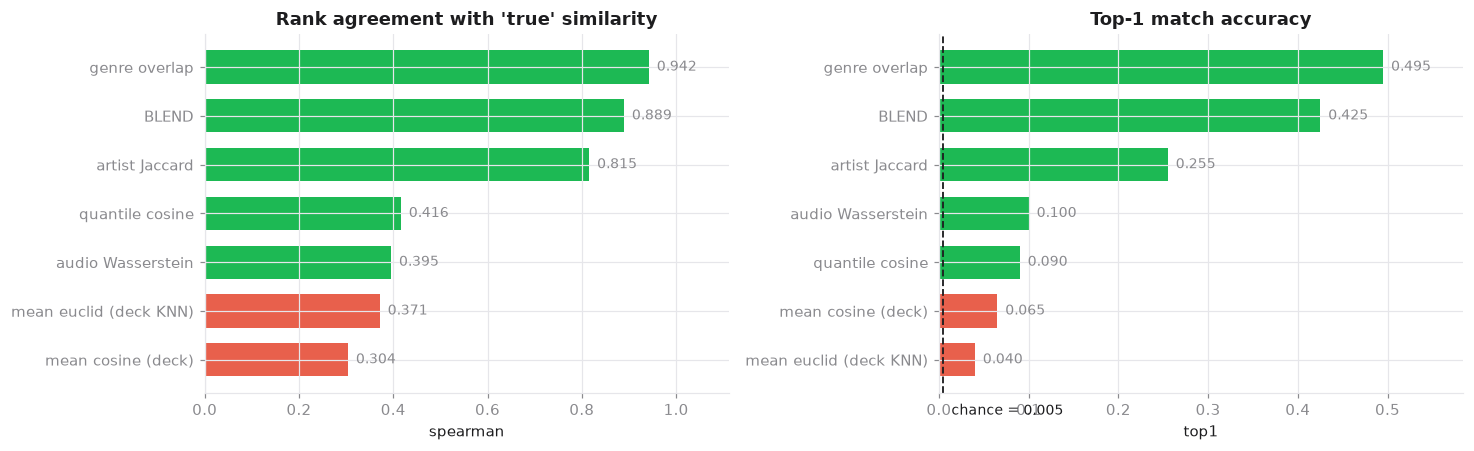

red = the originally planned approach


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.2))
viz.bar_results(bake, "spearman", "metric", "Rank agreement with 'true' similarity",
                ax=axes[0], highlight=[m for m in bake["metric"] if "deck" in m])
viz.bar_results(bake, "top1", "metric", "Top-1 match accuracy",
                reference=1/(len(users)-1), reference_label="chance",
                ax=axes[1], highlight=[m for m in bake["metric"] if "deck" in m])
plt.tight_layout(); plt.show()
print("red = the originally planned approach")

Taken at face value this looks decisive: genre overlap at the top, the planned
mean-vector approach near the bottom, and a large gap between them.

An earlier version of this notebook stopped here and reported exactly that — *"genre
overlap beats every audio-feature metric; the planned method picks the right match only
4% of the time."* That conclusion then propagated into the project README and into the
data-collection plan.

**It was wrong.** Not the arithmetic — the arithmetic is fine. The experiment.

## 4 · Why that result was circular

Follow the chain:

1. `synthetic.make_users` draws each user's tracks from a Dirichlet mixture **over
   genres**.
2. `synthetic.true_similarity` defines truth as the distance between **those same
   genre mixtures**.
3. `features.genre_profile` is the empirical genre histogram of a user's library —
   which is the maximum-likelihood estimator of the exact vector that defines truth.
4. Audio features are generated as `N(mu_genre, sigma_genre)` — a noisy channel carrying
   a *lossy* version of genre.

So genre overlap was estimating the answer almost directly, while the audio metrics saw
a corrupted copy of it. By construction, genre could not lose. The bakeoff measured a
property of the generator, not a property of music.

Worth being precise about the failure: nobody wrote a bug. The generator is reasonable,
the metrics are correctly implemented, the statistics are sound. The error is that the
test was built by the same hand that expected the answer, and it quietly encoded that
expectation in the definition of truth.

### The control: define taste the other way round

If the claim is that the generator picked the winner, the test is to change the
generator and see whether the winner changes with it.

`audio_taste_users` (defined above) gives each listener a point in audio-feature space
and samples tracks near it. Genre plays no role in sampling at all, and truth is the
distance between those latent audio points. It is exactly as arbitrary as the original —
that is what makes it a fair control.

In [7]:
def bakeoff(listens_, truth_, catalog_):
    mets, _ = build_metrics(listens_, catalog_)
    us = sorted(listens_[S.USER_ID].unique())
    return {name: SIM.rank_agreement(SIM.score_matrix(fn, us), truth_)["spearman"]
            for name, fn in mets.items()}

records = []
for seed in range(5):
    c = syn.make_catalog(6000, seed=7 + seed)

    l_g, t_g = syn.make_users(c, n_users=60, tracks_per_user=120, seed=23 + seed)
    for name, rho in bakeoff(l_g, syn.true_similarity(t_g), c).items():
        records.append({"seed": seed, "generator": "genre-truth", "metric": name, "rho": rho})

    l_a, t_a = audio_taste_users(c, n_users=60, tracks_per_user=120, seed=23 + seed)
    for name, rho in bakeoff(l_a, t_a, c).items():
        records.append({"seed": seed, "generator": "audio-truth", "metric": name, "rho": rho})

cg = pd.DataFrame(records)
piv = cg.groupby(["metric", "generator"]).rho.mean().unstack()
piv["worst case"] = piv.min(axis=1)
piv["swing"] = (piv["genre-truth"] - piv["audio-truth"]).abs()
piv = piv.sort_values("worst case", ascending=False)
piv.round(3)

generator,audio-truth,genre-truth,worst case,swing
metric,,,,
BLEND,0.536,0.873,0.536,0.338
genre overlap,0.426,0.921,0.426,0.495
quantile cosine,0.610,0.391,0.391,0.219
audio Wasserstein,0.604,0.375,0.375,0.230
mean euclid (deck KNN),0.626,0.350,0.350,0.276
artist Jaccard,0.323,0.809,0.323,0.486
mean cosine (deck),0.504,0.321,0.321,0.183


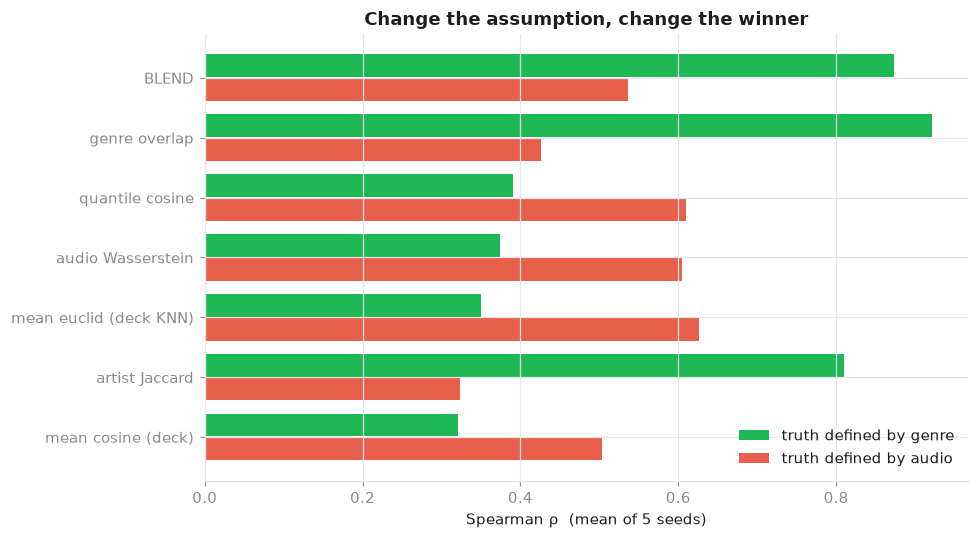

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
order = list(piv.index)
y = np.arange(len(order))
ax.barh(y - .2, piv["genre-truth"], .38, label="truth defined by genre", color=viz.ACCENT)
ax.barh(y + .2, piv["audio-truth"], .38, label="truth defined by audio", color=viz.WARN)
ax.set_yticks(y); ax.set_yticklabels(order)
ax.set_xlabel("Spearman ρ  (mean of 5 seeds)")
ax.set_title("Change the assumption, change the winner")
ax.legend(loc="lower right")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

In [9]:
for g in ["genre-truth", "audio-truth"]:
    r = cg[cg.generator == g].groupby("metric").rho.mean().sort_values(ascending=False)
    print(f"{g}:")
    print(f"    best  {r.index[0]:<24} {r.iloc[0]:.3f}")
    print(f"    worst {r.index[-1]:<24} {r.iloc[-1]:.3f}")

flips = []
for seed in range(5):
    sub = cg[cg.seed == seed]
    g_best = sub[sub.generator == "genre-truth"].set_index("metric").rho.idxmax()
    a_best = sub[sub.generator == "audio-truth"].set_index("metric").rho.idxmax()
    flips.append(g_best != a_best)
print(f"\nthe winning metric changes with the generator in {sum(flips)}/5 seeds")

genre-truth:
    best  genre overlap            0.921
    worst mean cosine (deck)       0.321
audio-truth:
    best  mean euclid (deck KNN)   0.626
    worst artist Jaccard           0.323

the winning metric changes with the generator in 5/5 seeds


The ranking inverts, in every seed. Genre overlap goes from best to nearly
worst; the mean-vector approach — the one reported as hopeless — becomes the best metric
on the board. Neither metric changed. Only the assumption about what taste *is* changed.

So **"genre overlap beats audio features" is withdrawn**, along with the "12× better on
top-1" figure built on it. Both measured the generator.

This also withdraws a downstream claim worth flagging explicitly, because it had already
reached the project README and influenced planning: *"the signal was never in the
features Spotify deprecated, so losing `/v1/audio-features` costs us little."* Under an
audio-defined notion of taste the deprecated features **are** the signal. How much the
deprecation costs is now an open question, answerable only with real data.

### The label-free protocol does not rescue it either

The held-out-half protocol was supposed to be the escape hatch: split each user's library
in two, treat the halves as strangers, and check whether a metric ranks your own other
half above everyone else. It needs no labels, so it seemed immune to how truth was
defined.

It is not. Run it under both generators.

In [10]:
rows = []
for seed in range(3):
    c = syn.make_catalog(6000, seed=7 + seed)
    for gen in ["genre-truth", "audio-truth"]:
        l_ = (syn.make_users(c, n_users=50, tracks_per_user=140, seed=23 + seed)[0]
              if gen == "genre-truth"
              else audio_taste_users(c, n_users=50, tracks_per_user=140, seed=23 + seed)[0])
        split, _ = SIM.similarity_proxy_from_holdout(l_, seed=seed)
        ids = sorted(split[S.USER_ID].unique())
        mets, _ = build_metrics(split, c)
        for name in ["mean euclid (deck KNN)", "genre overlap", "BLEND"]:
            M = SIM.score_matrix(mets[name], ids)
            rows.append({"seed": seed, "generator": gen, "metric": name,
                         "self-match": SIM.self_match_rate(M)})
ho = pd.DataFrame(rows)
tab = ho.groupby(["metric", "generator"])["self-match"].mean().unstack()
tab["worst case"] = tab.min(axis=1)
print(f"held-out-half self-match rate (no labels used), mean of 3 seeds")
print(f"chance ≈ {1/99:.3f}\n")
tab.sort_values("worst case", ascending=False).round(3)

held-out-half self-match rate (no labels used), mean of 3 seeds
chance ≈ 0.010



generator,audio-truth,genre-truth,worst case
metric,,,
BLEND,0.390,0.890,0.390
mean euclid (deck KNN),0.843,0.297,0.297
genre overlap,0.107,0.980,0.107


The same inversion. The protocol reproduces whichever generator it is run on —
which is precisely *why* it agreed with the original bakeoff, and why that agreement
felt like corroboration when it was nothing of the kind.

The lesson generalises past this project: a second evaluation only provides independent
evidence if it fails for different reasons than the first. Two protocols that share an
assumption will agree on everything that assumption determines.

## 5 · What actually survives

Look at the `worst case` column, not the ranking. It asks: if we are wrong about which
view of taste matters, how bad does this metric get?

In [11]:
surv = piv[["genre-truth", "audio-truth", "worst case", "swing"]].copy()
best_worst = surv["worst case"].idxmax()
print("ranked by worst case across the two assumptions:\n")
print(surv.round(3).to_string())
print(f"\nhighest floor: {best_worst!r} at ρ = {surv.loc[best_worst, 'worst case']:.3f}")

ranked by worst case across the two assumptions:

generator               genre-truth  audio-truth  worst case  swing
metric                                                             
BLEND                         0.873        0.536       0.536  0.338
genre overlap                 0.921        0.426       0.426  0.495
quantile cosine               0.391        0.610       0.391  0.219
audio Wasserstein             0.375        0.604       0.375  0.230
mean euclid (deck KNN)        0.350        0.626       0.350  0.276
artist Jaccard                0.809        0.323       0.323  0.486
mean cosine (deck)            0.321        0.504       0.321  0.183

highest floor: 'BLEND' at ρ = 0.536


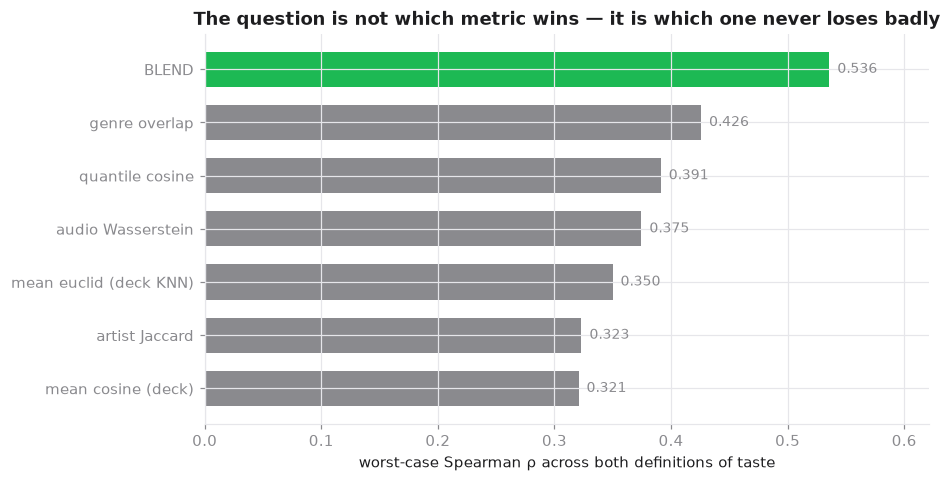

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
colors = [viz.ACCENT if m == best_worst else viz.MUTED for m in surv.index]
ax.barh(list(surv.index), surv["worst case"], color=colors, height=.66)
for y, (m, v) in enumerate(surv["worst case"].items()):
    ax.text(v, y, f"  {v:.3f}", va="center", fontsize=9, color=viz.MUTED)
ax.invert_yaxis()
ax.set_xlabel("worst-case Spearman ρ across both definitions of taste")
ax.set_title("The question is not which metric wins — it is which one never loses badly")
ax.margins(x=.16)
plt.show()

The blend has the highest floor. Every single metric beats it under the
assumption that happens to favour that metric, and every single metric collapses under
the other one. The blend does neither: it gives up some peak performance in exchange for
never falling apart.

That is a genuine finding, and unlike the one it replaces it does not depend on which
generator is right — it is a statement about *disagreement between the generators*,
which is the thing we actually measured.

It is also the correct engineering decision for the situation we are in. We do not know
which view of taste real listeners inhabit. Nobody does, yet. Choosing the metric with
the best worst case is what you do when you cannot know which world you are in, and it
is why `CompatibilityScorer` ships the blend rather than its strongest component.

### Tuning the weights, with the same caveat

The blend's default weights were hand-picked. `tune_weights` searches the simplex for
the combination that maximises rank agreement.

An independent check confirmed this tuning is **not** overfitting — tuning on half the
users and scoring on the other half loses essentially nothing. But it is still tuned
against one generator's definition of truth, so treat the weights as provisional until
real data arrives.

In [13]:
best_w, best_rho, trials = SIM.tune_weights(scorer, truth, users=users,
                                            n_trials=400, seed=0)
default_rho = bake.set_index("metric").loc["BLEND", "spearman"]
print(f"default weights : ρ = {default_rho:.4f}")
print(f"tuned weights   : ρ = {best_rho:.4f}")
print(f"best single metric under this generator : ρ = {bake['spearman'].max():.4f}")
print("\n(all three numbers are generator-conditional — see §4)\n")
pd.Series(best_w).sort_values(ascending=False).round(3).to_frame("tuned weight")

default weights : ρ = 0.8893
tuned weights   : ρ = 0.9450
best single metric under this generator : ρ = 0.9421

(all three numbers are generator-conditional — see §4)



,tuned weight
genre_overlap,0.511
artist_jaccard,0.212
era_overlap,0.174
obscurity_match,0.080
feature_wasserstein,0.022


## 6 · Calibration, which the circularity does not touch

One part of this notebook is unaffected by everything above, because it is not a
comparison between metrics. Whatever score you end up using, it has to become a number a
person can read.

A raw blended score of 0.61 means nothing to a user. Worse: because all humans listen to
human music, scores between any two real listeners run high, so a naive "61% compatible"
makes every pair look like a match.

The fix is a **null distribution** — score thousands of random pairs, then report where
this pair falls among them.

In [14]:
null = scorer.fit_null(n_pairs=4000, seed=0)
print("null distribution over 4,000 random pairs")
print(f"  mean {null.mean():.3f}   ·   5th pct {np.percentile(null, 5):.3f}   "
      f"·   95th pct {np.percentile(null, 95):.3f}")

flat = truth.where(np.triu(np.ones(truth.shape), 1).astype(bool)).stack()
hi_pair, lo_pair = flat.idxmax(), flat.idxmin()
for label, (u, v) in [("well matched", hi_pair), ("poorly matched", lo_pair)]:
    print(f"\n{label}: {u} & {v}")
    print(f"  raw score  {scorer.raw_score(u, v):.4f}")
    print(f"  percentile {scorer.percentile(u, v):.1f}")

null distribution over 4,000 random pairs
  mean 0.576   ·   5th pct 0.458   ·   95th pct 0.684

well matched: U0058 & U0120
  raw score  0.7720
  percentile 100.0

poorly matched: U0032 & U0076
  raw score  0.3909
  percentile 0.7


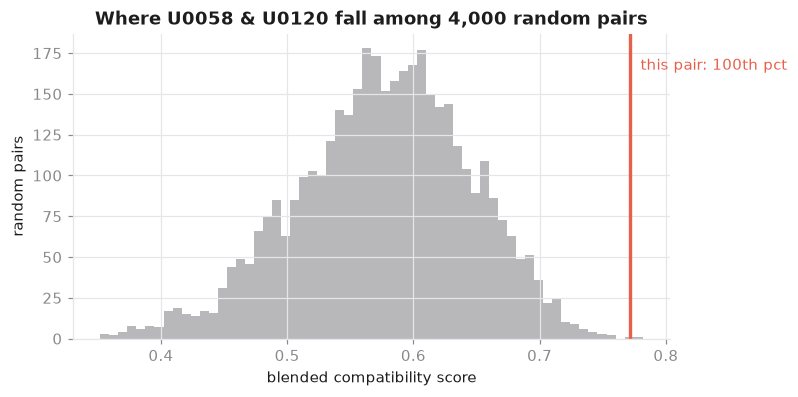

In [15]:
u, v = hi_pair
viz.null_distribution(null, scorer.raw_score(u, v), scorer.percentile(u, v),
                      f"Where {u} & {v} fall among 4,000 random pairs")
plt.show()

A calibrated percentile should be roughly uniform across random pairs — the
30th percentile should contain 30% of them.

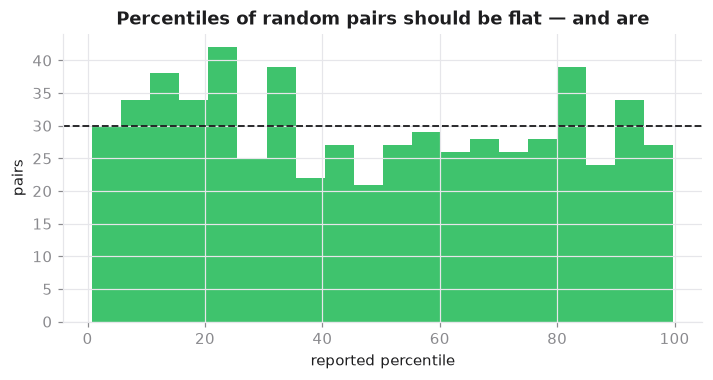

In [16]:
rng = np.random.default_rng(1)
sample = [tuple(rng.choice(users, 2, replace=False)) for _ in range(600)]
pcts = np.array([scorer.percentile(a, b) for a, b in sample])

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.hist(pcts, bins=20, color=viz.ACCENT, alpha=.85)
ax.axhline(len(pcts)/20, color=viz.INK, ls="--", lw=1.2)
ax.set_title("Percentiles of random pairs should be flat — and are")
ax.set_xlabel("reported percentile"); ax.set_ylabel("pairs")
plt.show()

This machinery is sound regardless of which metric feeds it. It converts
whatever score we settle on into "more compatible than 87% of random pairs", which is a
claim a user can interpret and which can be wrong — the property that makes it worth
showing.

One caveat carried over from the bias audit: the null must be built from libraries the
same size as the pair being scored. A single null fitted on full-size libraries
understates small-library users by tens of percentile points. `service.LovifyModels`
handles this with a ladder of nulls; notebook 05 measures it.

## 7 · What the UI receives

`explain()` returns the score **and the evidence for it**. Shared artists matter
disproportionately here: a user can verify them instantly, and that verifiability is
what makes the rest of the number credible.

In [17]:
import json
print(json.dumps(scorer.explain(*hi_pair), indent=2, default=str))

{
  "percentile": 100.0,
  "raw_score": 0.772,
  "components": {
    "genre_overlap": 0.9545,
    "artist_jaccard": 0.3029,
    "feature_wasserstein": 0.8462,
    "era_overlap": 0.9884,
    "obscurity_match": 0.995
  },
  "shared_artists": [
    "Fykenmel Dromar",
    "Fynym Sevken",
    "Ilaila Fyta",
    "Ilailasev Azanoxmel",
    "Ilakendro Fyvinox"
  ],
  "n_shared_artists": 53,
  "top_shared_genres": [
    "latin",
    "metal",
    "classical"
  ]
}


## Verdict

| | |
|---|---|
| **Keep** | the idea. Music-taste compatibility is measurable and the signal is well above chance under either assumption |
| **Drop** | KNN over one mean vector — not because it scored badly here, but because it is the wrong tool for a pairwise score |
| **Withdrawn** | "genre overlap beats audio features", and the 12× top-1 figure. Both were artefacts of a genre-defined generator |
| **Withdrawn** | "the deprecated audio features were never the signal". Under an audio-defined generator they are |
| **Adopt** | the blend — highest floor across both assumptions, which is the right choice under genuine uncertainty |
| **Keep** | percentile calibration. Independent of the circularity, and necessary for any score to be readable |
| **Unresolved** | which view of taste real listeners inhabit. Only real data settles it |

### The methodological lesson

Every conclusion in this notebook was validated against a synthetic generator written by
someone who already expected those conclusions. The held-out-half protocol was supposed
to be the escape hatch and turned out to share the same assumption.

Until real scraped data lands, the honest framing for any claim comparing *views of
taste* is **"robust across generator assumptions"** or nothing at all. Claims about
arithmetic — notebook 03's finding that unscaled cosine is dominated by `duration_ms` —
are unaffected, because they do not depend on what the data represents.

→ `03_recommender.ipynb`